# 3.5 Bivariate LISA: do children and poor walking access cluster together? (H-c as proposed)

**H-c (proposal):** subzones with many young children and low walking accessibility form spatial
clusters, i.e. demand concentrates where the centre network is thin.

- H0: no bivariate spatial association between child density and the neighbours' walk time to the
  nearest centre (bivariate Moran's I = 0).
- H1: positive bivariate association (dense-child subzones are surrounded by long-walk subzones).

Tested with the bivariate Moran's I and local bivariate LISA (`esda`), Queen contiguity with islands
attached to the nearest neighbour, 9,999 permutations, on the 140 HDB subzones with at least 100
children 0-6. Two accessibility measures: child-weighted walk time to the nearest centre (H-c quadrant =
high-high) and log centres per 1,000 children (H-c quadrant = high-low). This is the record of the
rejected proposal-form H-c; the reframed analysis (supply pressure) is 3.7. Code: Minh's
`scripts/lisa_hc.py` plus the Moran scatter from `scripts/make_deck_figures.py`.

**Inputs**
- `output/hdb_blocks.gpkg`, layer `subzone_stats` (stage 1): child density, walk time, centres per 1,000 children.

**Outputs**
- `output/subzone_lisa_hc.csv` (140 subzones: bivariate quadrant label and pseudo-p for both specifications).
- `figures/hc_bivariate_moran.png`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyogrio
from esda.moran import Moran, Moran_BV, Moran_Local_BV
from matplotlib.patches import Patch

from bt4015.maps import BLUE, GRID, INK, INK2, INK3, LISA, tidy, use_deck_style
from bt4015.spatial_weights import queen_with_islands_patched

warnings.filterwarnings("ignore")
use_deck_style()
MIN_CHILDREN, PERMS, SEED = 100, 9999, 4015
LAB = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}   # esda quadrant codes

## 1. Subzones and weights

HDB subzones with at least 100 children 0-6 (decision 2026-11-02), Queen contiguity with the two
islands (Teban Gardens, Marine Parade) attached to their nearest neighbour so every unit has a lag.

In [2]:
# 1. Subzone statistics with geometry; filter to analysable HDB subzones.
np.random.seed(SEED)   # esda's permutations use numpy's global state
s = pyogrio.read_dataframe(OUT / "hdb_blocks.gpkg", layer="subzone_stats")
h = s[s["has_hdb"] & (s["children_0_6"] >= MIN_CHILDREN)].reset_index(drop=True)
w = queen_with_islands_patched(h)
print(f"{len(h)} HDB subzones with >= {MIN_CHILDREN} children; Queen contiguity, "
      f"mean neighbours {w.mean_neighbors:.2f}, islands after patching: {len(w.islands)}")

# 2. Demand x = child density; two access measures y.
x = h["child_density_0_6_km2"].to_numpy(float)
specs = {"walk": ("walk_nearest_min_cw", h["walk_nearest_min_cw"].to_numpy(float), "HH"),
         "sup": ("log centres per 1,000 children", np.log1p(h["centres_per_1000_children_0_6"].to_numpy(float)), "HL")}

140 HDB subzones with >= 100 children; Queen contiguity, mean neighbours 4.13, islands after patching: 0


## 2. Bivariate Moran's I and local bivariate LISA

For each access measure: the global bivariate I of child density against the spatial lag of access,
and the local version per subzone. The "H-c quadrant" is where the hypothesis would put its weak
links: high density next to high walk time (HH), or high density next to low supply (HL).

In [3]:
global_results = {}
for key, (name, y, bad) in specs.items():
    # 1. Global bivariate I with permutation p; local bivariate LISA with quadrant + pseudo-p.
    g = Moran_BV(x, y, w, permutations=PERMS)
    loc = Moran_Local_BV(x, y, w, permutations=PERMS)
    sig = loc.p_sim < 0.05
    h[f"bv_{key}_q"] = [LAB[q] if sg else "ns" for q, sg in zip(loc.q, sig)]
    h[f"bv_{key}_p"] = loc.p_sim
    counts = pd.Series([LAB[q] for q in loc.q[sig]]).value_counts().to_dict()
    global_results[key] = (g.I, g.p_sim)
    print(f"child density vs {name}: bivariate I = {g.I:+.3f}, p = {g.p_sim:.4f}; "
          f"H-c quadrant {bad}: {counts.get(bad, 0)} subzones; all significant: {counts}")
    print(h.loc[h[f"bv_{key}_q"] == bad, ["SUBZONE_N", "PLN_AREA_N", "children_0_6", "walk_nearest_min_cw",
                                           "centres_per_1000_children_0_6", f"bv_{key}_p"]].round(2).to_string(index=False), "\n")

child density vs walk_nearest_min_cw: bivariate I = -0.191, p = 0.0002; H-c quadrant HH: 2 subzones; all significant: {'LH': 11, 'HL': 11, 'LL': 4, 'HH': 2}
          SUBZONE_N  PLN_AREA_N  children_0_6  walk_nearest_min_cw  centres_per_1000_children_0_6  bv_walk_p
        TIONG BAHRU BUKIT MERAH        505.45                 3.16                           5.94       0.05
TIONG BAHRU STATION BUKIT MERAH        522.86                 3.88                           5.74       0.01 

child density vs log centres per 1,000 children: bivariate I = -0.067, p = 0.0967; H-c quadrant HL: 4 subzones; all significant: {'LH': 8, 'LL': 5, 'HL': 4, 'HH': 2}
          SUBZONE_N PLN_AREA_N  children_0_6  walk_nearest_min_cw  centres_per_1000_children_0_6  bv_sup_p
    PASIR RIS DRIVE  PASIR RIS       2099.46                 3.66                           8.10      0.05
         PLANTATION     TENGAH       1960.00                 3.37                           2.04      0.02
             GARDEN     TEN

In [4]:
# 2. Univariate Moran's I of each input, for context, and the plain correlation of demand and supply.
for n, v in (("child density", x), ("walk time", specs["walk"][1]), ("log supply", specs["sup"][1])):
    m = Moran(v, w, permutations=PERMS)
    print(f"univariate Moran's I, {n}: {m.I:+.3f} (p = {m.p_sim:.4f})")
print("Pearson r, child density vs log centres per 1,000 children:", round(np.corrcoef(x, specs["sup"][1])[0, 1], 3))
h.drop(columns="geometry").to_csv(OUT / "subzone_lisa_hc.csv", index=False)
print(f"wrote {OUT.relative_to(ROOT)}/subzone_lisa_hc.csv ({len(h)} rows)")

univariate Moran's I, child density: +0.164 (p = 0.0064)


univariate Moran's I, walk time: +0.211 (p = 0.0005)
univariate Moran's I, log supply: +0.119 (p = 0.0243)
Pearson r, child density vs log centres per 1,000 children: -0.646
wrote output/subzone_lisa_hc.csv (140 rows)


## 3. Moran scatter: child density against the neighbours' walk time

The deck figure. The bivariate I computed by hand here (standardised x against the row-standardised
lag of standardised y) equals the `esda` value above.

bivariate I by hand = -0.191; esda = -0.191 (p = 0.0002)


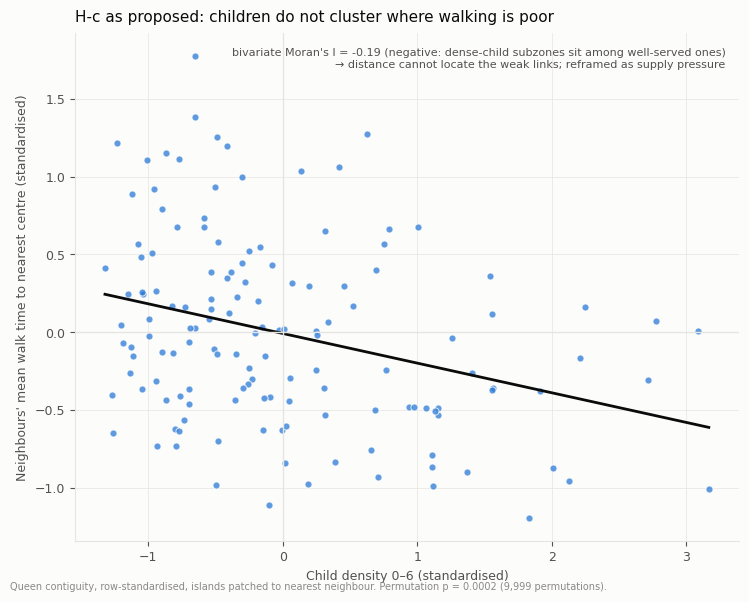

In [5]:
zx = (h["child_density_0_6_km2"] - h["child_density_0_6_km2"].mean()) / h["child_density_0_6_km2"].std()
zy = (h["walk_nearest_min_cw"] - h["walk_nearest_min_cw"].mean()) / h["walk_nearest_min_cw"].std()
lag = w.sparse @ zy.to_numpy()
I_bv = float((zx * lag).sum() / (zx ** 2).sum())
print(f"bivariate I by hand = {I_bv:+.3f}; esda = {global_results['walk'][0]:+.3f} (p = {global_results['walk'][1]:.4f})")
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(zx, lag, s=26, color=BLUE, alpha=0.75, edgecolor="white", linewidth=0.8)
b = np.polyfit(zx, lag, 1)
xs = np.linspace(zx.min(), zx.max(), 20)
ax.plot(xs, np.polyval(b, xs), color=INK, lw=2)
ax.axhline(0, color=GRID, lw=1); ax.axvline(0, color=GRID, lw=1)
ax.set_xlabel("Child density 0–6 (standardised)")
ax.set_ylabel("Neighbours' mean walk time to nearest centre (standardised)")
ax.set_title("H-c as proposed: children do not cluster where walking is poor", loc="left", fontsize=11, pad=8)
ax.text(0.98, 0.97, f"bivariate Moran's I = {I_bv:+.2f} (negative: dense-child subzones sit among well-served ones)\n"
        "→ distance cannot locate the weak links; reframed as supply pressure", transform=ax.transAxes, va="top",
        ha="right", fontsize=8, color=INK2)
tidy(ax)
fig.text(0.01, 0.01, f"Queen contiguity, row-standardised, islands patched to nearest neighbour. Permutation p = "
         f"{global_results['walk'][1]:.4f} ({PERMS:,} permutations).", fontsize=7, color=INK3)
fig.tight_layout()
fig.savefig(FIG / "hc_bivariate_moran.png", dpi=170)
plt.show()

## 4. Map of the local bivariate clusters (walk-time specification)

Shown for the record (not a deck figure): the few significant high-high subzones are isolated, and
most of the significant local associations are low-high or high-low, the opposite of H-c.

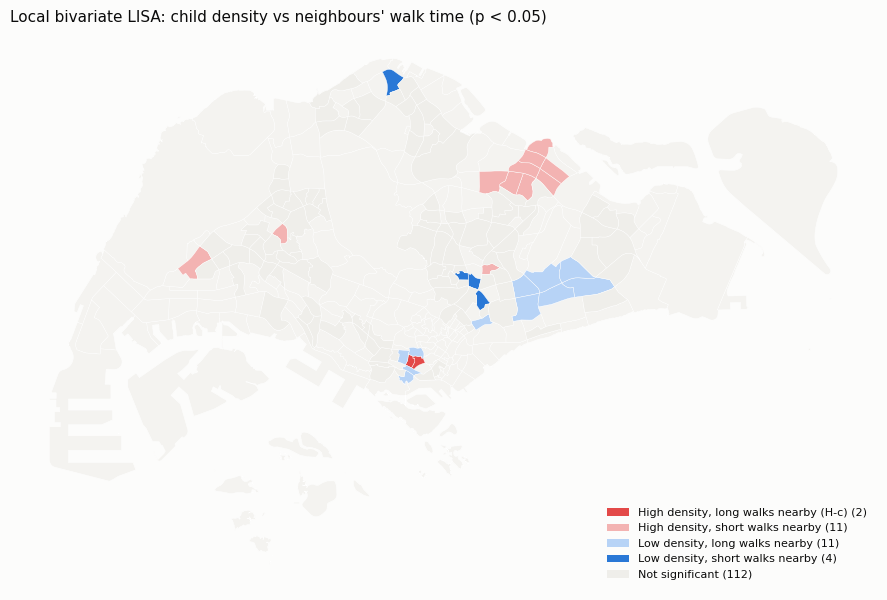

In [6]:
sz_all = pyogrio.read_dataframe(OUT / "hdb_blocks.gpkg", layer="subzones")
fig, ax = plt.subplots(figsize=(9, 6))
sz_all.plot(ax=ax, color="#f4f3f0", edgecolor="white", linewidth=0.3)
for lab, colr in LISA.items():
    g = h[h["bv_walk_q"].eq(lab)]
    if len(g):
        g.plot(ax=ax, color=colr, edgecolor="white", linewidth=0.3)
ax.set_axis_off()
ax.set_title("Local bivariate LISA: child density vs neighbours' walk time (p < 0.05)", loc="left", fontsize=11, pad=8)
names = {"HH": "High density, long walks nearby (H-c)", "HL": "High density, short walks nearby", "LH": "Low density, long walks nearby",
         "LL": "Low density, short walks nearby", "ns": "Not significant"}
ax.legend(handles=[Patch(facecolor=LISA[k], edgecolor="none", label=f"{names[k]} ({int((h['bv_walk_q'] == k).sum())})") for k in LISA],
          loc="lower right", frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

## 5. Verdict

**H-c as proposed is rejected.** The bivariate Moran's I of child density against neighbouring walk
time is negative and significant (about -0.19, p < 0.001): the subzones with the most young children
are surrounded by subzones with *short* walks, because the new towns were built with centres in the
void decks. Against log supply per child the association is also negative and only a handful of
subzones fall in the high-density/low-supply quadrant. Distance therefore cannot locate the weak
links. The prof's reframing (30 Oct) is to ask how many children share each reachable centre, the
supply-pressure index of 3.7.

In [7]:
print(f"written: {OUT.relative_to(ROOT)}/subzone_lisa_hc.csv ({len(h)} rows), {FIG.relative_to(ROOT)}/hc_bivariate_moran.png")

written: output/subzone_lisa_hc.csv (140 rows), figures/hc_bivariate_moran.png
